# Задачи 6–7. Прогнозирование связей и узлов в сети объектов капитального строительства

**Тема КР:** «Разработка сети объектов капитального строительства на территории страны».
Сеть — железнодорожная сеть России из Wikidata: узлы — станции, рёбра — перегоны (подробно в ноутбуке КР).

**Содержание**
- **6. Аналитическая записка**
  - 6.1 Метод прогнозирования связей и узлов: постановка, семейства методов, особенности, метрики, протокол оценки.
  - 6.2 Реальные задачи, решаемые методом.
  - 6.3 Решение: (а) прогноз недостающих перегонов (link prediction) — эвристики, Katz, DeepWalk/node2vec, GraphSAGE;
    (б) прогноз атрибута узла — года открытия станции (node regression).
- **7. Реферативный обзор** дополнительных источников (12 работ).

## 6.1 Описание метода

### Предсказание связей (link prediction)
**Постановка.** Дан граф $G=(V,E)$ и, возможно, признаки узлов $X$. Нужно для пары $(u,v)\notin E$ оценить score $s(u,v)$ —
правдоподобие того, что ребро существует, но не наблюдается (пропуск в данных), или появится в будущем.
Модель обучается как бинарный классификатор пар: позитивы — существующие рёбра, негативы — сэмплированные несвязанные пары.

**Семейства методов**
| Семейство | Идея | Примеры | Особенности |
|---|---|---|---|
| Локальные эвристики | общие соседи | Common Neighbors, Jaccard, Adamic–Adar $\sum_{w\in\Gamma(u)\cap\Gamma(v)} 1/\log k_w$, Resource Allocation, Preferential Attachment $k_u k_v$ | без обучения, интерпретируемы; бесполезны, если у пары нет общих соседей |
| Глобальные эвристики | все пути между узлами | Katz $\sum_{l\ge1}\beta^l (A^l)_{uv}$, Rooted PageRank, SimRank | учитывают длинные пути, дороже по вычислениям |
| Эмбеддинги (shallow) | близость в векторном пространстве | DeepWalk, node2vec, LINE; score $= f(z_u \odot z_v)$ | трансдуктивны, не используют признаки |
| GNN (encoder–decoder) | $z = \mathrm{GNN}(X, A)$, $s=\mathrm{dec}(z_u, z_v)$ | GCN, GraphSAGE, GAT, VGAE | используют и структуру, и признаки; GraphSAGE индуктивен |
| GNN на подграфе пары | классификация окрестности пары | SEAL (DRNL-разметка) | выразительнее: «видит» общие соседей и пути, но дорог |

### Предсказание узлов (node classification / regression)
Предсказать метку или числовое свойство $y_v$ узла по его признакам и окрестности. Работает принцип **гомофилии**: соседние
узлы похожи. Методы: label propagation, MLP по признакам (без графа), GNN (GCN/GraphSAGE/GAT, APPNP).

### Метрики и протокол оценки
- **ROC-AUC** — вероятность того, что случайный позитив получит score выше случайного негатива.
- **AP (average precision)** — площадь под кривой precision–recall; чувствительна к началу ранжирования.
- **Precision@K** — доля настоящих рёбер среди $K$ пар с наивысшим score (так работает практика: проверяются топ-K кандидатов).
- **Hits@K** (OGB) — доля позитивов, получивших score выше $K$-го лучшего негатива.
- **Регрессия узлов:** MAE, $R^2$. **Классификация:** accuracy, macro-F1, матрица ошибок.

**Протокол:** часть рёбер скрывается (у нас 15% — тест, 5% — валидация). Модели и эвристики видят только оставшийся граф.
Важен **выбор негативов**: случайные пары в пространственной сети почти всегда далеко друг от друга, и задача становится тривиальной.
Поэтому мы дополнительно оцениваем на **«трудных» негативах**: географически близких, но не связанных станциях
(как в HeaRT-протоколе Li et al., 2023).

## 6.2 Реальные задачи, решаемые методом

**В строительстве и инфраструктуре**
1. Восстановление пропущенных связей в реестрах и BIM/ГИС-данных (недостающие перегоны, трубопроводы, дверные проёмы) — контроль качества данных.
2. Планирование новых линий («хорд»): ранжирование пар объектов, связь между которыми даёт наибольший эффект.
3. Поиск недостающих технологических зависимостей в сетевом графике работ.
4. Рекомендация связей «поставщик – объект» в логистике стройплощадки.
5. Классификация объектов (назначение помещения, класс станции, уровень аварийности участка сети) и заполнение пропущенных атрибутов
   (год ввода, регион — как в 6.3б).
6. Прогноз отказов узлов инженерных сетей по состоянию соседей.

**В других областях МО на графах**
7. Рекомендательные системы (пользователь – товар), «возможно, вы знакомы» в соцсетях.
8. Достраивание графов знаний (Wikidata, Freebase): пропущенные факты.
9. Биоинформатика: белок-белковые взаимодействия, взаимодействия лекарств (drug–drug, drug–target).
10. Наукометрия: прогноз соавторства и цитирований.
11. Антифрод: связи между аккаунтами и транзакциями; классификация мошеннических узлов.
12. Транспорт: прогноз загрузки участков, восстановление дорожного графа по трекам.

## 6.3 Решение задачи прогнозирования

### Данные

In [1]:
# ---------- Загрузка (с кэшем) и подготовка данных ----------
import os, io, time, json, math, random, warnings
from collections import Counter
import numpy as np, pandas as pd, requests, networkx as nx
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
UA = {"User-Agent": "GraphML-coursework/1.0 (educational)", "Accept": "text/csv"}

def sparql(query, path):
    """Запрос к Wikidata Query Service с кэшированием результата в CSV."""
    if not os.path.exists(path):
        r = requests.get("https://query.wikidata.org/sparql", params={"query": query}, headers=UA, timeout=300)
        r.raise_for_status()
        open(path, "w", encoding="utf-8").write(r.text)
    return pd.read_csv(path)

STATION = "wd:Q55488"   # железнодорожная станция
raw_nodes = sparql(f"""SELECT ?s ?sLabel ?coord ?open ?adm WHERE {{
  ?s wdt:P31 {STATION}; wdt:P17 wd:Q159; wdt:P625 ?coord . FILTER EXISTS {{ ?s wdt:P197 ?x }}
  OPTIONAL {{ ?s wdt:P1619 ?open }} OPTIONAL {{ ?s wdt:P131 ?adm }}
  SERVICE wikibase:label {{ bd:serviceParam wikibase:language "ru,en". }} }}""", "data/nodes_raw.csv")
raw_edges = sparql(f"""SELECT ?s ?a WHERE {{ ?s wdt:P31 {STATION}; wdt:P17 wd:Q159; wdt:P197 ?a . ?a wdt:P31 {STATION} . }}""",
                   "data/edges_raw.csv")
regions = sparql("""SELECT ?reg ?regLabel ?fd ?fdLabel ?pop WHERE { ?reg wdt:P31 wd:Q43263 .
  OPTIONAL { ?reg wdt:P361 ?fd . ?fd wdt:P31 wd:Q484215 } OPTIONAL { ?reg wdt:P1082 ?pop }
  SERVICE wikibase:label { bd:serviceParam wikibase:language "ru". } }""", "data/regions.csv")
regions = regions.sort_values("pop", ascending=False).drop_duplicates("reg")

# Административная единица станции (район/город) -> субъект РФ: поднимаемся по P131 пакетами
if not os.path.exists("data/adm_region.csv"):
    regset, parent, resolved = set(regions.reg), {}, {}
    adms = set(raw_nodes.adm.dropna())
    resolved.update({a: a for a in adms & regset})
    cur = {a: a for a in adms - regset}
    for _ in range(8):
        todo = sorted(set(cur.values()) - set(parent))
        for i in range(0, len(todo), 400):
            vals = " ".join("wd:" + x.rsplit("/", 1)[1] for x in todo[i:i + 400])
            r = requests.get("https://query.wikidata.org/sparql", headers=UA, timeout=300,
                             params={"query": f"SELECT ?a ?p WHERE {{ VALUES ?a {{ {vals} }} ?a wdt:P131 ?p }}"})
            for a, g in pd.read_csv(io.StringIO(r.text)).groupby("a"):
                parent[a] = list(g.p)
            time.sleep(1)
        nxt = {}
        for orig, c in cur.items():
            hit = [p for p in parent.get(c, []) if p in regset]
            if hit: resolved[orig] = hit[0]
            elif parent.get(c): nxt[orig] = parent[c][0]
        cur = nxt
        if not cur: break
    pd.DataFrame(list(resolved.items()), columns=["adm", "reg"]).to_csv("data/adm_region.csv", index=False)
adm_region = pd.read_csv("data/adm_region.csv")

# Узлы
xy = raw_nodes.coord.str.extract(r"Point\(([-\d.]+) ([-\d.]+)\)").astype(float)
raw_nodes["lon"], raw_nodes["lat"] = xy[0], xy[1]
raw_nodes["year"] = pd.to_datetime(raw_nodes.open, errors="coerce", utc=True).dt.year
nodes = (raw_nodes.groupby("s").agg(name=("sLabel", "first"), lon=("lon", "first"), lat=("lat", "first"),
                                     year=("year", "min"), adm=("adm", "first")).reset_index()
         .merge(adm_region, on="adm", how="left")
         .merge(regions[["reg", "regLabel", "fdLabel", "pop"]], on="reg", how="left"))
nodes["qid"] = nodes.s.str.rsplit("/", n=1).str[1]
nodes = nodes.rename(columns={"regLabel": "region", "fdLabel": "district", "pop": "region_pop"})
nodes["district"] = nodes["district"].str.replace(" федеральный округ", "", regex=False)

def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(h))

# Рёбра: смежность станций (P197) -> неориентированный перегон, вес = длина по прямой, км
e = raw_edges[raw_edges.s != raw_edges.a].copy()
e[["u", "v"]] = np.sort(e[["s", "a"]].values, axis=1)
e = e.drop_duplicates(["u", "v"])
pos_ix = nodes.set_index("s")
e = e[e.u.isin(pos_ix.index) & e.v.isin(pos_ix.index)]
e["km"] = haversine(pos_ix.loc[e.u, "lon"].values, pos_ix.loc[e.u, "lat"].values,
                    pos_ix.loc[e.v, "lon"].values, pos_ix.loc[e.v, "lat"].values)
e = e[e.km <= 150]                       # единичные ошибки разметки ("соседи" за сотни км)

idx = {s: i for i, s in enumerate(nodes.s)}
nodes.insert(0, "id", range(len(nodes)))
edges = pd.DataFrame({"src": e.u.map(idx).values, "dst": e.v.map(idx).values, "km": e.km.round(3).values})
edges["type"] = "перегон"
nodes.drop(columns=["s", "adm", "reg"]).to_csv("nodes.csv", index=False)
edges.to_csv("edges.csv", index=False)

G = nx.Graph()
for r in nodes.itertuples():
    G.add_node(r.id, name=r.name, lon=r.lon, lat=r.lat, year=r.year, region=r.region, district=r.district)
G.add_weighted_edges_from(edges[["src", "dst", "km"]].values, weight="km")
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
LCC = G.subgraph(max(nx.connected_components(G), key=len)).copy()
POS = {n: (G.nodes[n]["lon"], G.nodes[n]["lat"]) for n in G}
DISTRICTS = sorted(nodes.district.dropna().unique())
DCOLOR = dict(zip(DISTRICTS, plt.get_cmap("tab10").colors))

def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

def geo_axes(ax):
    ax.set_aspect(1 / np.cos(np.radians(55)))       # равнопромежуточная проекция с поправкой на широту
    ax.set_xlabel("долгота"); ax.set_ylabel("широта")

print(f"Станций (узлов): {G.number_of_nodes()}, перегонов (рёбер): {G.number_of_edges()}, "
      f"крупнейшая компонента: {LCC.number_of_nodes()} узлов")

Станций (узлов): 10625, перегонов (рёбер): 10834, крупнейшая компонента: 9950 узлов


### 6.3(а) Прогноз недостающих перегонов (link prediction)

**Разбиение.** Рёбра перемешиваются: 15% — тест, 5% — валидация, 80% — обучающий граф.
**Негативы:** *случайные* — равномерные пары станций; *трудные* — для каждого конца тестового ребра выбирается одна из 8
ближайших по расстоянию станций, не связанная с ним в полном графе.

In [2]:
import torch, torch.nn.functional as F
from sklearn.neighbors import BallTree
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

torch.manual_seed(SEED)
nl = sorted(G); N = len(nl); remap = {n: i for i, n in enumerate(nl)}
lon = np.array([G.nodes[n]["lon"] for n in nl]); lat = np.array([G.nodes[n]["lat"] for n in nl])
E_all = np.array([(remap[u], remap[v]) for u, v in G.edges()])
E_set = {tuple(sorted(e)) for e in E_all}

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(E_all))
n_te, n_va = int(0.15 * len(E_all)), int(0.05 * len(E_all))
E_te, E_va, E_tr = E_all[perm[:n_te]], E_all[perm[n_te:n_te + n_va]], E_all[perm[n_te + n_va:]]

tree = BallTree(np.radians(np.c_[lat, lon]), metric="haversine")
_, KNN = tree.query(np.radians(np.c_[lat, lon]), k=9)            # 8 ближайших + сам узел

def random_neg(n, exclude):
    out = set()
    while len(out) < n:
        a, b = rng.integers(N, size=2)
        if a != b and (min(a, b), max(a, b)) not in exclude:
            out.add((min(a, b), max(a, b)))
    return np.array(sorted(out))

def hard_neg(pos, exclude):
    out = set()
    for u, v in pos:
        for a in (u, v):
            cand = [b for b in KNN[a][1:] if (min(a, b), max(a, b)) not in exclude and (min(a, b), max(a, b)) not in out]
            if cand:
                b = cand[rng.integers(len(cand))]; out.add((min(a, b), max(a, b)))
                break
    return np.array(sorted(out))

neg = {("test", "случайные"): random_neg(len(E_te), E_set), ("test", "трудные"): hard_neg(E_te, E_set),
       ("val", "случайные"): random_neg(len(E_va), E_set), ("val", "трудные"): hard_neg(E_va, E_set)}
dist = lambda P: haversine(lon[P[:, 0]], lat[P[:, 0]], lon[P[:, 1]], lat[P[:, 1]])
print(f"train/val/test рёбер: {len(E_tr)}/{len(E_va)}/{len(E_te)}")
print(f"Медианное расстояние, км: тестовые рёбра {np.median(dist(E_te)):.1f}, случайные негативы "
      f"{np.median(dist(neg[('test', 'случайные')])):.0f}, трудные негативы {np.median(dist(neg[('test', 'трудные')])):.1f}")

Gtr = nx.Graph(); Gtr.add_nodes_from(range(N)); Gtr.add_edges_from(E_tr.tolist())
print(f"Граф после удаления тестовых/вал. рёбер: {nx.number_connected_components(Gtr)} компонент (было {nx.number_connected_components(G)})")

train/val/test рёбер: 8668/541/1625
Медианное расстояние, км: тестовые рёбра 4.7, случайные негативы 1408, трудные негативы 12.3
Граф после удаления тестовых/вал. рёбер: 2009 компонент (было 39)


In [3]:
import scipy.sparse as sp

def heuristic_scores(P, g):
    pairs = [tuple(map(int, p)) for p in P]
    return {
        "Common Neighbors": np.array([len(list(nx.common_neighbors(g, u, v))) for u, v in pairs], float),
        "Jaccard": np.array([s for *_, s in nx.jaccard_coefficient(g, pairs)]),
        "Adamic-Adar": np.array([s for *_, s in nx.adamic_adar_index(g, pairs)]),
        "Resource Allocation": np.array([s for *_, s in nx.resource_allocation_index(g, pairs)]),
        "Pref. Attachment": np.array([s for *_, s in nx.preferential_attachment(g, pairs)], float),
    }

A_tr = nx.to_scipy_sparse_array(Gtr, nodelist=range(N), format="csr").astype(np.float32)

def katz(P, beta=0.5, L=30):
    """Усечённый индекс Каца: sum_{l<=L} beta^l (A^l)_uv. Длинные пути нужны, т.к. граф цепочечный."""
    src = np.unique(P[:, 0]); col = {s: j for j, s in enumerate(src)}
    X = sp.csr_matrix((np.ones(len(src), np.float32), (src, np.arange(len(src)))), shape=(N, len(src)))
    S = sp.csr_matrix((N, len(src)), dtype=np.float32)
    for l in range(1, L + 1):
        X = A_tr @ X
        S = S + (beta ** l) * X
    S = S.tocsc()
    return np.array([S[v, col[u]] for u, v in P], dtype=float)

def shortest_path_score(P):
    out = []
    for u, v in P:
        try: out.append(-nx.shortest_path_length(Gtr, int(u), int(v)))
        except nx.NetworkXNoPath: out.append(-1e6)
    return np.array(out, float)

**Единый протокол обучения.** Обучаемые модели (эмбеддинги, классификатор по признакам пары, GNN) учатся предсказывать рёбра,
**отсутствующие** в графе, на котором они «смотрят» на структуру. Для этого 30% train-рёбер (`E_sup`) убираются из графа
передачи сообщений и блужданий (`E_mp`) и служат позитивами обучения, так же как тестовые рёбра отсутствуют в train-графе.
Без такого разделения модель учится на рёбрах, которые она «видит», а тестирует на невидимых. Это распределительный сдвиг,
из-за которого AUC может упасть ниже 0.5.

**Признаки пары** (идея heuristic-augmented GNN и SEAL: модели нужна информация о взаимном положении пары в графе):
расстояние (log км), степени концов, связаны ли узлы в оставшемся графе и длина пути между ними (с отсечкой 40).

In [4]:
k_sup = int(0.3 * len(E_tr))
E_sup, E_mp = E_tr[:k_sup], E_tr[k_sup:]
Gmp = nx.Graph(); Gmp.add_nodes_from(range(N)); Gmp.add_edges_from(E_mp.tolist())

def pair_features(P, g, cutoff=40):
    deg = np.array([g.degree(i) for i in range(N)])
    comp = {n: c for c, cc in enumerate(nx.connected_components(g)) for n in cc}
    hops = []
    for u, v in P:
        d = nx.single_source_shortest_path_length(g, int(u), cutoff=cutoff).get(int(v)) if comp[u] == comp[v] else None
        hops.append(cutoff + 10 if d is None else d)
    du, dv = deg[P[:, 0]], deg[P[:, 1]]
    return np.c_[np.log1p(dist(P)), np.minimum(du, dv), np.maximum(du, dv),
                 [comp[u] == comp[v] for u, v in P], np.log1p(hops)].astype(np.float32)

tr_neg = np.vstack([random_neg(len(E_sup) // 2, E_set), hard_neg(E_sup[: len(E_sup) // 2], E_set)])
P_fit = np.vstack([E_sup, tr_neg]); y_fit = np.r_[np.ones(len(E_sup)), np.zeros(len(tr_neg))]
PF_fit = pair_features(P_fit, Gmp)            # признаки считаются на графе БЕЗ этих рёбер
pf_scaler = StandardScaler().fit(PF_fit)
print("Обучающих пар:", len(P_fit))

Обучающих пар: 5200


In [5]:
# DeepWalk и node2vec: случайные блуждания по графу E_mp + Word2Vec (skip-gram)
from gensim.models import Word2Vec

def walks(g, num=10, length=40, p=1.0, q=1.0, seed=SEED):
    adj = [list(g.neighbors(i)) for i in range(N)]
    r = random.Random(seed); out = []
    for _ in range(num):
        order = list(range(N)); r.shuffle(order)
        for s in order:
            if not adj[s]: continue
            w = [s, r.choice(adj[s])]
            while len(w) < length:
                cur, prev = w[-1], w[-2]
                nb = adj[cur]
                if p == 1 and q == 1:
                    w.append(r.choice(nb)); continue
                # node2vec: вес 1/p за возврат, 1 - общий сосед с prev, 1/q - уход дальше
                ws = [1 / p if x == prev else (1.0 if x in adj[prev] else 1 / q) for x in nb]
                w.append(r.choices(nb, weights=ws)[0])
            out.append([str(x) for x in w])
    return out

def embed(g, p, q):
    m = Word2Vec(walks(g, p=p, q=q), vector_size=64, window=5, min_count=0, sg=1, negative=5, workers=1, epochs=1, seed=SEED)
    Z = np.zeros((N, 64), np.float32)
    for i in range(N):
        if str(i) in m.wv: Z[i] = m.wv[str(i)]
    return Z

def emb_clf(Z):
    hp = lambda P: np.c_[Z[P[:, 0]] * Z[P[:, 1]], np.abs(Z[P[:, 0]] - Z[P[:, 1]])]
    clf = LogisticRegression(max_iter=3000).fit(hp(P_fit), y_fit)
    return lambda P: clf.predict_proba(hp(P))[:, 1]

t0 = time.time()
score_dw = emb_clf(embed(Gmp, 1, 1))          # DeepWalk
score_n2v = emb_clf(embed(Gmp, 1, 0.5))       # node2vec, q<1 - уход вглубь (DFS-подобно)
print(f"Эмбеддинги построены за {time.time() - t0:.0f} с")

# Классификатор по признакам пары (градиентный бустинг) - «пространственно-топологическая» модель без GNN
from sklearn.ensemble import HistGradientBoostingClassifier
gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED).fit(PF_fit, y_fit)

Эмбеддинги построены за 13 с


In [6]:
# GraphSAGE: признаки узлов + передача сообщений по графу, декодер - MLP над (z_u * z_v, |z_u - z_v|, признаки пары)
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import to_undirected

yr = np.array([G.nodes[n]["year"] for n in nl], float)
node_feat = lambda g: torch.tensor(StandardScaler().fit_transform(
    np.c_[lon, lat, np.nan_to_num(yr, nan=np.nanmedian(yr)), np.isnan(yr), [g.degree(i) for i in range(N)]]), dtype=torch.float)
X_mp, X_tr = node_feat(Gmp), node_feat(Gtr)
ei_mp = to_undirected(torch.tensor(E_mp.T, dtype=torch.long), num_nodes=N)
ei_tr = to_undirected(torch.tensor(E_tr.T, dtype=torch.long), num_nodes=N)

class LinkSAGE(torch.nn.Module):
    def __init__(self, d, d_pair, h=64, use_pair=True):
        super().__init__()
        self.use_pair = use_pair
        self.c1, self.c2 = SAGEConv(d, h), SAGEConv(h, h)
        self.dec = torch.nn.Sequential(torch.nn.Linear(2 * h + (d_pair if use_pair else 0), h), torch.nn.ReLU(),
                                       torch.nn.Linear(h, 1))
    def encode(self, x, ei):
        return self.c2(F.relu(self.c1(x, ei)), ei)
    def score(self, z, P, pf):
        a, b = z[P[:, 0]], z[P[:, 1]]
        parts = [a * b, (a - b).abs()] + ([pf] if self.use_pair else [])
        return self.dec(torch.cat(parts, 1)).squeeze(-1)

PF_fit_t = torch.tensor(pf_scaler.transform(PF_fit), dtype=torch.float)
Pva = np.vstack([E_va, neg[("val", "трудные")], neg[("val", "случайные")]])
yva = np.r_[np.ones(len(E_va)), np.zeros(len(Pva) - len(E_va))]
PF_va = torch.tensor(pf_scaler.transform(pair_features(Pva, Gtr)), dtype=torch.float)

def train_sage(use_pair):
    torch.manual_seed(SEED)
    m = LinkSAGE(X_mp.size(1), PF_fit.shape[1], use_pair=use_pair); o = torch.optim.Adam(m.parameters(), lr=0.005)
    Pt, yt_ = torch.tensor(P_fit), torch.tensor(y_fit, dtype=torch.float)
    best, st = 0, None
    for ep in range(300):
        m.train(); o.zero_grad()
        F.binary_cross_entropy_with_logits(m.score(m.encode(X_mp, ei_mp), Pt, PF_fit_t), yt_).backward(); o.step()
        m.eval()
        with torch.no_grad():
            auc = roc_auc_score(yva, m.score(m.encode(X_tr, ei_tr), torch.tensor(Pva), PF_va).numpy())
        if auc > best: best, st = auc, {k: v.clone() for k, v in m.state_dict().items()}
    m.load_state_dict(st); m.eval()
    print(f"GraphSAGE ({'с признаками пары' if use_pair else 'только эмбеддинги'}): лучший val ROC-AUC = {best:.4f}")
    return m

sage_plain, sage_pair = train_sage(False), train_sage(True)

def sage_scorer(m, x, ei, g):
    with torch.no_grad():
        z = m.encode(x, ei)
    def f(P):
        pf = torch.tensor(pf_scaler.transform(pair_features(P, g)), dtype=torch.float)
        with torch.no_grad():
            return torch.sigmoid(m.score(z, torch.tensor(P), pf)).numpy()
    return f
score_sage = sage_scorer(sage_plain, X_tr, ei_tr, Gtr)
score_sage_pair = sage_scorer(sage_pair, X_tr, ei_tr, Gtr)

GraphSAGE (только эмбеддинги): лучший val ROC-AUC = 0.8946


GraphSAGE (с признаками пары): лучший val ROC-AUC = 0.9303


In [7]:
def precision_at_k(y, s, k=100):
    return y[np.argsort(-s)[:k]].mean()

def hits_at_k(y, s, k=50):
    negs = np.sort(s[y == 0])[::-1]
    return (s[y == 1] > negs[min(k, len(negs)) - 1]).mean()

rows = []
for regime in ["случайные", "трудные"]:
    P = np.vstack([E_te, neg[("test", regime)]]); y = np.r_[np.ones(len(E_te)), np.zeros(len(neg[("test", regime)]))]
    scores = heuristic_scores(P, Gtr)
    scores["Katz (β=0.5, L≤30)"] = katz(P)
    scores["Кратчайший путь в графе"] = shortest_path_score(P)
    scores["Расстояние (−км)"] = -dist(P)
    scores["DeepWalk + LogReg"] = score_dw(P)
    scores["node2vec + LogReg"] = score_n2v(P)
    scores["GBM по признакам пары"] = gbm.predict_proba(pair_features(P, Gtr))[:, 1]
    scores["GraphSAGE (эмбеддинги узлов)"] = score_sage(P)
    scores["GraphSAGE + признаки пары"] = score_sage_pair(P)
    for name, s in scores.items():
        rows.append({"негативы": regime, "метод": name, "ROC-AUC": roc_auc_score(y, s), "AP": average_precision_score(y, s),
                     "P@100": precision_at_k(y, s), "Hits@50": hits_at_k(y, s)})
lp = pd.DataFrame(rows).round(4)
lp_wide = lp.pivot(index="метод", columns="негативы", values=["ROC-AUC", "AP", "Hits@50"])
lp_wide = lp_wide.sort_values(("ROC-AUC", "трудные"), ascending=False)
lp_wide

ROC-AUC                AP           Hits@50  \
негативы                     случайные трудные случайные трудные случайные   
метод                                                                        
GBM по признакам пары           0.9994  0.8964    0.9995  0.8802    0.9994   
GraphSAGE + признаки пары       0.9977  0.8634    0.9978  0.8395    0.9772   
Расстояние (−км)                0.9997  0.8108    0.9996  0.8048    1.0000   
GraphSAGE (эмбеддинги узлов)    0.9905  0.7981    0.9885  0.7479    0.9231   
node2vec + LogReg               0.7066  0.6172    0.6963  0.6002    0.0000   
DeepWalk + LogReg               0.7025  0.6148    0.6964  0.6000    0.0000   
Common Neighbors                0.5046  0.4376    0.5044  0.4969    0.0098   
Adamic-Adar                     0.5046  0.4373    0.5042  0.4968    0.0098   
Jaccard                         0.5046  0.4373    0.5036  0.4956    0.0098   
Resource Allocation             0.5046  0.4373    0.5042  0.4968    0.0098   
Katz (β=0.5, L≤30)              0.5111  0.3743    0.5113  0.4938    0.0228   
Кратчайший путь в графе         0.5111  0.3721    0.5104  0.4901    0.0228   
Pref. Attachment                0.1238  0.3038    0.4124  0.4469    0.0006   

                                      
негативы                     трудные  
метод                                 
GBM по признакам пары         0.3280  
GraphSAGE + признаки пары     0.2480  
Расстояние (−км)              0.2825  
GraphSAGE (эмбеддинги узлов)  0.0991  
node2vec + LogReg             0.0000  
DeepWalk + LogReg             0.0000  
Common Neighbors              0.0012  
Adamic-Adar                   0.0012  
Jaccard                       0.0018  
Resource Allocation           0.0012  
Katz (β=0.5, L≤30)            0.0098  
Кратчайший путь в графе       0.0000  
Pref. Attachment              0.0049

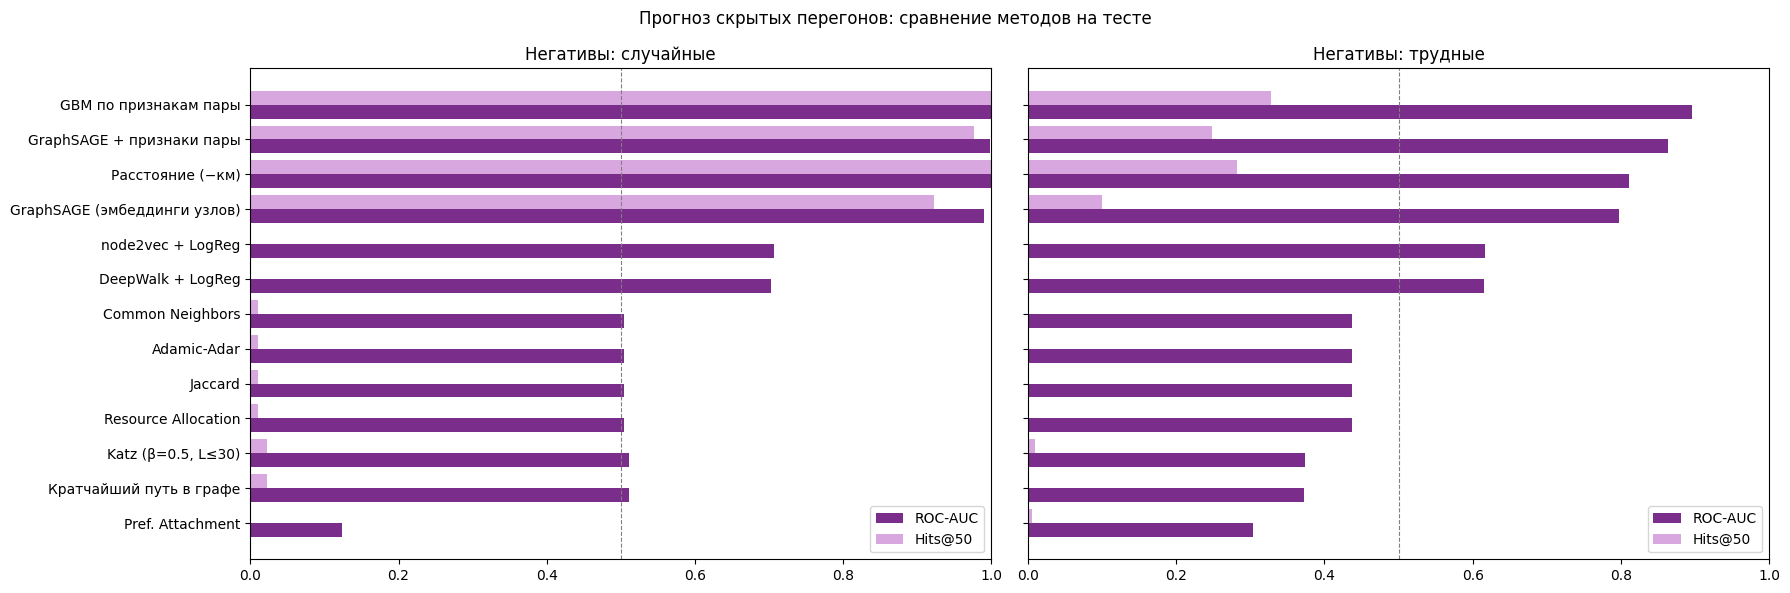

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
order = lp_wide.index.tolist()[::-1]
for ax, regime in zip(axes, ["случайные", "трудные"]):
    d = lp[lp["негативы"] == regime].set_index("метод").loc[order]
    ax.barh(np.arange(len(d)) - 0.2, d["ROC-AUC"], 0.4, label="ROC-AUC", color="#7b2d8b")
    ax.barh(np.arange(len(d)) + 0.2, d["Hits@50"], 0.4, label="Hits@50", color="#d8a7e0")
    ax.axvline(0.5, color="gray", ls="--", lw=0.8)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index); ax.set_xlim(0, 1)
    ax.set_title(f"Негативы: {regime}"); ax.legend(loc="lower right")
plt.suptitle("Прогноз скрытых перегонов: сравнение методов на тесте")
plt.tight_layout(); savefig("10_link_prediction_metrics"); plt.show()

**Анализ результатов link prediction** (тест, 1625 скрытых перегонов)
- **Локальные эвристики (CN, Jaccard, AA, RA)** в ж/д сети не работают (ROC-AUC ≈ 0.5): у соседних станций на линии нет общих
  соседей (треугольников почти нет), score = 0 и для позитивов, и для негативов. **Katz и кратчайший путь** тоже ≈ 0.5:
  удаление 20% перегонов разрывает цепочечную сеть на ~2000 фрагментов, и между концами скрытого перегона чаще всего нет пути.
  Preferential Attachment даже ниже 0.5: концы скрытого перегона в оставшемся графе имеют пониженную степень.
- **DeepWalk / node2vec** (≈ 0.70 на случайных и ≈ 0.62 на трудных негативах) лучше эвристик, но слабы: эмбеддинги чисто структурные, а структура в месте разрыва потеряна.
- **Расстояние** — почти идеальный предиктор против случайных негативов (они в среднем за 1400 км), но на трудных негативах
  (ближайшие станции, медиана 12 км) ROC-AUC падает до ≈ 0.81.
- **GraphSAGE** с одними эмбеддингами узлов: ≈ 0.80 на трудных негативах. С **признаками пары** (расстояние, степени концов,
  связность и длина пути в оставшемся графе): ≈ 0.86.
- **Лучший результат** (≈ 0.90 ROC-AUC, AP ≈ 0.88 на трудных) у градиентного бустинга по тем же признакам пары. Сочетание признаков
  «концы пары рядом, их степень понижена, короткого пути между ними нет» описывает разрыв линии точнее, чем узловые эмбеддинги GNN.

**Вывод о методе.** В пространственных инфраструктурных сетях топологические эвристики, созданные для социальных сетей
(триадическое замыкание), неприменимы. Решающую роль играют геометрия и признаки пары (как в SEAL / heuristic-augmented GNN).
GNN полезна как источник признаков узлов, но сама по себе не превосходит хорошо сконструированные признаки пары.
Оценка на случайных негативах завышает качество почти всех методов до ≈ 1.0. Корректна только оценка на трудных негативах
(вывод Li et al., 2023).

### Применение: кандидаты в недостающие или новые перегоны
Лучшей моделью оцениваются все пары станций в радиусе 15 км, не связанные в графе, у которых путь по сети длиннее 20 перегонов
или отсутствует. Это либо **пропуски в данных** (перегон есть в реальности, но не внесён в Wikidata), либо **кандидаты на
соединительную линию**, которая сокращает путь. Общий топ занимают Московский и Петербургский узлы: там много близких, но «далёких по сети»
вокзалов и станций МЦК/МЦД (часть их связей в Wikidata не заполнена). Поэтому показываем также лучшую пару в каждом регионе.

Лучшая модель по ROC-AUC на трудных негативах: GBM по признакам пары


Общий топ-5:


,станция 1,станция 2,регион,км,"путь по сети, перегонов",score
0,Беговая,Москва-Сити,Москва,2.8,нет пути,0.998
1,Северный пост,Нижегородская,Москва,2.2,нет пути,0.998
2,Северный пост,Новохохловская,Москва,2.3,нет пути,0.998
3,Боровая,Волковская,Санкт-Петербург,2.2,нет пути,0.998
4,Северный пост,Сортировочная,Москва,2.2,нет пути,0.998


Лучший кандидат в каждом регионе:


,станция 1,станция 2,регион,км,"путь по сети, перегонов",score
0,Беговая,Москва-Сити,Москва,2.8,нет пути,0.998
3,Боровая,Волковская,Санкт-Петербург,2.2,нет пути,0.998
35,20 км,Стрельня-Новая,Калининградская область,2.7,нет пути,0.991
110,Школьная,Локомотивная,Самарская область,1.6,26,0.944
129,Хухоямяки,Яккима,Карелия,5.0,нет пути,0.937
140,Тихие Зори,Железнодорожная больница,Красноярский край,2.1,23,0.935
191,Баковка,Солнечная,Московская область,5.2,нет пути,0.914
320,Невдубстрой,Невская Дубровка,Ленинградская область,5.1,37,0.833
384,687 км,692 км,Иркутская область,4.1,нет пути,0.792
669,1426 км,Пролётная,Республика Крым,7.9,нет пути,0.709


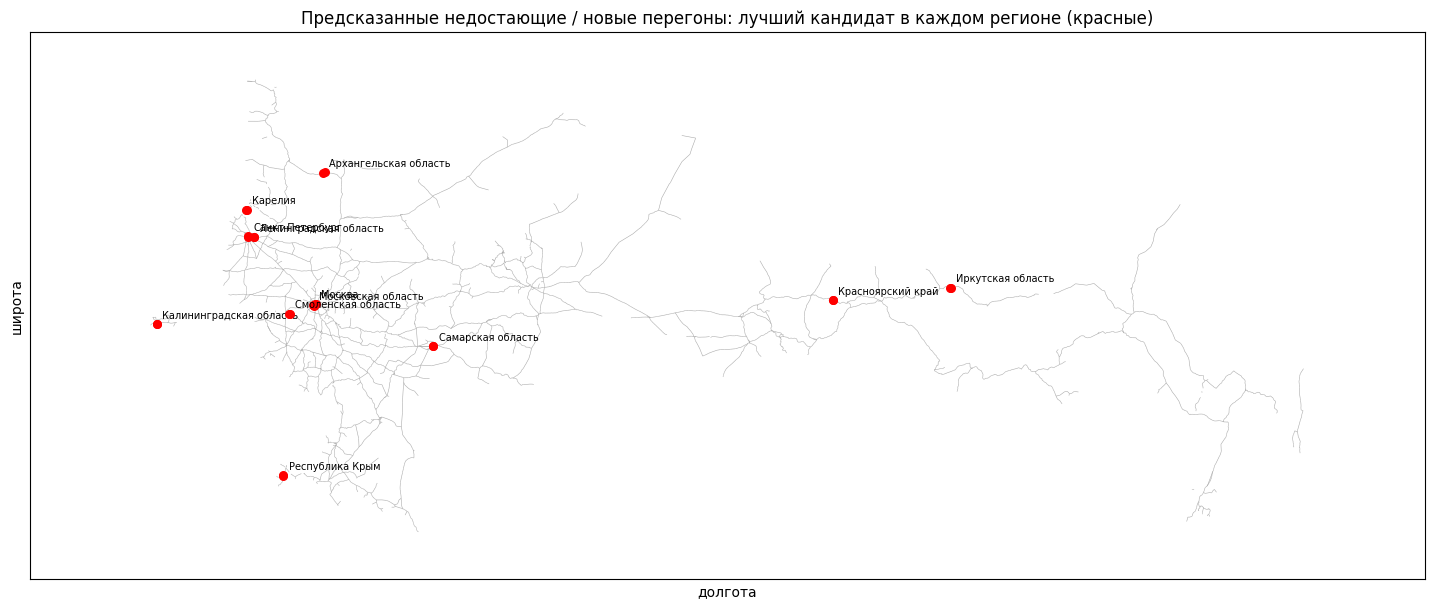

In [9]:
cand = set()
for i, js in enumerate(tree.query_radius(np.radians(np.c_[lat, lon]), r=15 / 6371.0)):
    for j in js:
        if i < j and (i, j) not in E_set:
            cand.add((i, j))
cand = np.array(sorted(cand))
Gfull = nx.relabel_nodes(G, remap)
comp = {n: c for c, cc in enumerate(nx.connected_components(Gfull)) for n in cc}

# применение лучшей модели к полному графу (все известные перегоны)
score_full = sage_scorer(sage_pair, node_feat(Gfull), to_undirected(torch.tensor(E_all.T, dtype=torch.long), num_nodes=N), Gfull)
best_name = lp_wide.index[0]
print("Лучшая модель по ROC-AUC на трудных негативах:", best_name)
gbm_full = lambda P: gbm.predict_proba(pair_features(P, Gfull))[:, 1]
s_c = gbm_full(cand) if best_name.startswith("GBM") else score_full(cand)
rows_c = []
for k in np.argsort(-s_c)[:3000]:
    u, v = cand[k]
    h = nx.shortest_path_length(Gfull, u, v) if comp[u] == comp[v] else np.inf
    if h > 20:
        rows_c.append({"станция 1": G.nodes[nl[u]]["name"], "станция 2": G.nodes[nl[v]]["name"],
                       "регион": G.nodes[nl[u]]["region"], "км": round(float(dist(cand[[k]])[0]), 1),
                       "путь по сети, перегонов": "нет пути" if np.isinf(h) else int(h), "score": round(float(s_c[k]), 3),
                       "u": u, "v": v})
allc = pd.DataFrame(rows_c)
print("Общий топ-5:"); display(allc.head(5).drop(columns=["u", "v"]))
rec = allc.dropna(subset=["регион"]).drop_duplicates("регион").head(15)
print("Лучший кандидат в каждом регионе:"); display(rec.drop(columns=["u", "v"]))

fig, ax = plt.subplots(figsize=(18, 8))
nx.draw_networkx_edges(G, POS, ax=ax, width=0.4, edge_color="#aaaaaa")
for r in rec.itertuples():
    a_, b_ = nl[r.u], nl[r.v]
    ax.plot([POS[a_][0], POS[b_][0]], [POS[a_][1], POS[b_][1]], color="red", lw=3)
    ax.scatter([POS[a_][0], POS[b_][0]], [POS[a_][1], POS[b_][1]], color="red", s=30, zorder=3)
    ax.annotate(r.регион, POS[a_], fontsize=7, xytext=(4, 4), textcoords="offset points")
geo_axes(ax); ax.set_title("Предсказанные недостающие / новые перегоны: лучший кандидат в каждом регионе (красные)")
savefig("11_predicted_links"); plt.show()

### 6.3(б) Прогноз свойства узла: год открытия станции (node regression)
Год открытия известен у ~65% станций. Восстанавливаем его для остальных: соседние станции одной линии строились одновременно
(гомофилия по году). Сравниваем медиану (без модели), MLP по признакам (без графа), распространение значений по соседям
и GraphSAGE. Признаки не содержат самого года.

In [10]:
from sklearn.metrics import mean_absolute_error, r2_score
known = np.where(~np.isnan(yr))[0]
tr_i, rest = known[rng.permutation(len(known))[: int(0.6 * len(known))]], None
rest = np.setdiff1d(known, tr_i); rest = rest[rng.permutation(len(rest))]
va_i, te_i = rest[: len(rest) // 2], rest[len(rest) // 2:]
ymu, ysd = yr[tr_i].mean(), yr[tr_i].std()
Xn = torch.tensor(StandardScaler().fit_transform(np.c_[lon, lat, [G.degree(n) for n in nl],
                  [np.log1p(np.mean([G[n][m]["km"] for m in G[n]])) for n in nl]]), dtype=torch.float)
ei_full = to_undirected(torch.tensor(E_all.T, dtype=torch.long), num_nodes=N)
yt = torch.tensor(np.nan_to_num((yr - ymu) / ysd), dtype=torch.float)

class Reg(torch.nn.Module):
    def __init__(self, graph, d, h=64):
        super().__init__(); self.graph = graph
        self.l1 = SAGEConv(d, h) if graph else torch.nn.Linear(d, h)
        self.l2 = SAGEConv(h, h) if graph else torch.nn.Linear(h, h)
        self.out = torch.nn.Linear(h, 1)
    def forward(self, x, ei):
        f = (lambda l, z: l(z, ei)) if self.graph else (lambda l, z: l(z))
        return self.out(F.relu(f(self.l2, F.relu(f(self.l1, x))))).squeeze(-1)

def fit_reg(graph):
    torch.manual_seed(SEED)
    m = Reg(graph, Xn.size(1)); o = torch.optim.Adam(m.parameters(), lr=0.01)
    best, st = 1e9, None
    for ep in range(500):
        m.train(); o.zero_grad(); F.l1_loss(m(Xn, ei_full)[tr_i], yt[tr_i]).backward(); o.step()
        m.eval(); v = F.l1_loss(m(Xn, ei_full)[va_i], yt[va_i]).item()
        if v < best: best, st = v, {k: x.clone() for k, x in m.state_dict().items()}
    m.load_state_dict(st); m.eval()
    return m(Xn, ei_full).detach().numpy() * ysd + ymu

def propagate(steps=300):
    """Распространение значений: неизвестный год = среднее по соседям, известные (train) закреплены."""
    A = nx.to_scipy_sparse_array(Gfull, nodelist=range(N), format="csr")
    deg_ = np.maximum(A.sum(1), 1)
    v = np.full(N, yr[tr_i].mean()); v[tr_i] = yr[tr_i]
    for _ in range(steps):
        v = A @ v / deg_; v[tr_i] = yr[tr_i]
    return v

preds_y = {"медиана (без модели)": np.full(N, np.median(yr[tr_i])), "MLP (признаки)": fit_reg(False),
           "распространение по соседям": propagate(), "GraphSAGE (признаки + граф)": fit_reg(True)}
reg_res = pd.DataFrame([{"метод": k, "MAE, лет": mean_absolute_error(yr[te_i], p[te_i]), "R²": r2_score(yr[te_i], p[te_i])}
                        for k, p in preds_y.items()]).round(3)
reg_res

,метод,"MAE, лет",R²
0,медиана (без модели),28.149,-0.001
1,MLP (признаки),22.431,0.225
2,распространение по соседям,20.854,0.139
3,GraphSAGE (признаки + граф),22.259,0.253


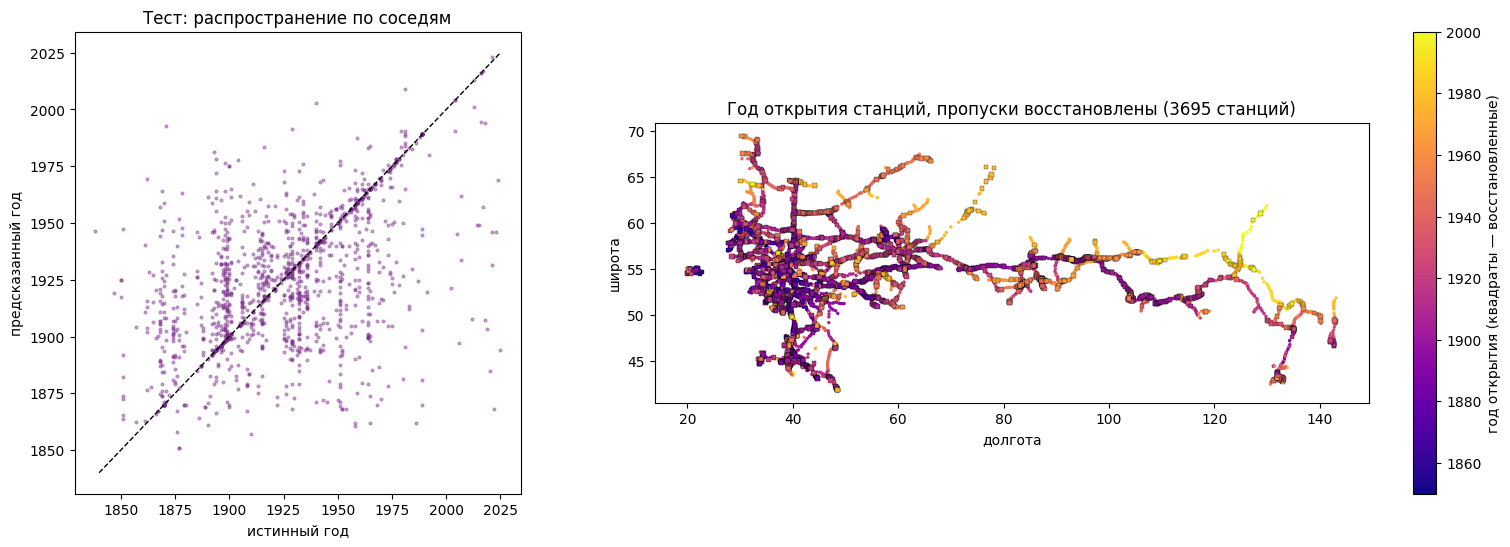

In [11]:
best_m = reg_res.sort_values("MAE, лет").iloc[0]["метод"]
p_best = preds_y[best_m]
miss = np.where(np.isnan(yr))[0]
fig, axes = plt.subplots(1, 2, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 2]})
axes[0].scatter(yr[te_i], p_best[te_i], s=4, alpha=0.4, color="#7b2d8b")
axes[0].plot([1840, 2025], [1840, 2025], "k--", lw=1)
axes[0].set_xlabel("истинный год"); axes[0].set_ylabel("предсказанный год"); axes[0].set_title(f"Тест: {best_m}")
yy = yr.copy(); yy[miss] = p_best[miss]
sc = axes[1].scatter(lon, lat, c=yy, s=2, cmap="plasma", vmin=1850, vmax=2000)
axes[1].scatter(lon[miss], lat[miss], c=yy[miss], s=10, cmap="plasma", vmin=1850, vmax=2000, marker="s", edgecolors="k", linewidths=0.2)
plt.colorbar(sc, ax=axes[1], label="год открытия (квадраты — восстановленные)")
geo_axes(axes[1]); axes[1].set_title(f"Год открытия станций, пропуски восстановлены ({len(miss)} станций)")
savefig("12_node_regression"); plt.show()

**Вывод по 6.3(б).**
- Год открытия предсказывается лишь умеренно. Распространение по соседям даёт наименьшую MAE (≈ 21 год против 28 у медианы),
  GraphSAGE и MLP — около 22 лет, $R^2 \le 0.25$.
- Причина в данных: в Wikidata указан год открытия конкретной станции, и на старых линиях много станций и остановочных
  пунктов, открытых позже самой линии. Поэтому гомофилия по году есть, но она шумная.
- Практический вывод: восстановленные значения годятся как приближённая оценка эпохи объекта (для приоритизации обследований),
  но не заменяют архивные данные.
- На карте видна история строительства: линии европейской части XIX века, Транссиб начала XX века, северные и восточные ветви
  второй половины XX века.

### Итог аналитической записки
| Задача | Лучший подход на наших данных | Почему |
|---|---|---|
| Пропущенные перегоны (рёбра) | признаки пары (расстояние, степени, путь) + GBM; GraphSAGE + признаки пары — близко | локальная топология пространственной сети бедна, решают геометрия и признаки пары |
| Округ станции (класс узла, ноутбук КР) | распространение меток / GNN с координатами | сильная гомофилия вдоль линий |
| Год открытия (значение узла) | распространение по соседям (MAE ≈ 21 год) | шумная гомофилия по эпохе строительства |

# 7. Реферативный обзор дополнительного материала

## 7.1 Задача и её значимость
**Предсказание связей** — оценка вероятности существования ребра между двумя узлами (пропущенного или будущего).
**Предсказание узлов** — определение метки или свойства узла по его признакам и признакам соседей. Обе задачи — базовые
«строительные блоки» машинного обучения на графах. На них держатся рекомендательные системы, достраивание графов знаний,
биомедицина (взаимодействия белков и лекарств) и, как показано в 6.3, контроль качества и планирование
инфраструктурных сетей. Значимость задач в том, что реальные графы всегда неполны, а проверять каждую пару объектов вручную невозможно.

## 7.2 Источники и почему они выбраны
Выбраны работы, которые задали каждое из семейств методов (эвристики → эмбеддинги → GNN → подграфовые GNN → динамика),
а также работы о протоколах оценки. Все — рецензируемые публикации ведущих площадок (KDD, WWW, NeurIPS, ICLR, ICML) или
классические журналы.

| № | Источник | Площадка | Ключевая идея | Результат / значение |
|---|---|---|---|---|
| 1 | Liben-Nowell D., Kleinberg J. *The link-prediction problem for social networks* | JASIST, 2007 | Формализация задачи link prediction; сравнение мер близости (CN, Jaccard, Adamic–Adar, Katz, PageRank) на сетях соавторства | Простые меры многократно лучше случайного угадывания; Adamic–Adar и Katz — среди лучших. Работа задала протокол «скрыть часть рёбер → восстановить» |
| 2 | Lü L., Zhou T. *Link prediction in complex networks: A survey* | Physica A, 2011 | Систематизация локальных, глобальных и квазилокальных индексов, вероятностных моделей | Индекс Resource Allocation; вывод, что качество эвристик зависит от класса сети |
| 3 | Katz L. *A new status index derived from sociometric analysis* | Psychometrika, 1953 | Сумма путей всех длин с затуханием $\beta^l$ | Основа глобальных эвристик; хорошо работает при длинных путях (полезен в цепочечных сетях, см. 6.3) |
| 4 | Perozzi B., Al-Rfou R., Skiena S. *DeepWalk: Online learning of social representations* | KDD, 2014 | Случайные блуждания как «предложения» + skip-gram (word2vec) | Первые эффективные эмбеддинги узлов; выигрыш на классификации узлов при малой доле меток |
| 5 | Tang J. et al. *LINE: Large-scale information network embedding* | WWW, 2015 | Сохранение близости 1-го (ребро) и 2-го (общие соседи) порядка, negative sampling | Масштабируемость на графы с миллионами узлов |
| 6 | Grover A., Leskovec J. *node2vec: Scalable feature learning for networks* | KDD, 2016 | Смещённые блуждания (p, q) между BFS и DFS; операторы над парой эмбеддингов (Адамар) для рёбер | Улучшение над DeepWalk/LINE в классификации узлов и link prediction |
| 7 | Kipf T., Welling M. *Semi-supervised classification with graph convolutional networks* | ICLR, 2017 | Свёртка как нормированное усреднение по соседям $\hat{A} X W$ | Сильный прирост в полуконтролируемой классификации узлов (Cora, Citeseer, Pubmed); стандартный бейзлайн. Для рёбер — VGAE (Kipf, Welling, 2016) |
| 8 | Hamilton W., Ying R., Leskovec J. *Inductive representation learning on large graphs* (GraphSAGE) | NeurIPS, 2017 | Сэмплирование соседей и обучаемые агрегаторы | Индуктивность: эмбеддинги для новых узлов без переобучения — критично для растущих сетей объектов |
| 9 | Veličković P. et al. *Graph attention networks* | ICLR, 2018 | Внимание: обучаемые веса соседей | Качество на уровне state-of-the-art на тот момент; интерпретируемые веса связей |
| 10 | Zhang M., Chen Y. *Link prediction based on graph neural networks* (SEAL) | NeurIPS, 2018 | Классификация замкнутого подграфа пары с разметкой узлов DRNL; теория γ-затухающих эвристик | Показано, что большинство эвристик выучиваются из локального подграфа; SEAL превзошёл эвристики и эмбеддинги |
| 11 | Hu W. et al. *Open Graph Benchmark* | NeurIPS, 2020 | Единые реалистичные датасеты и сплиты (например, по времени), метрики Hits@K, MRR | Воспроизводимое сравнение; видно, что простые эвристики часто конкурентны с GNN |
| 12 | Li J. et al. *Evaluating graph neural networks for link prediction: current pitfalls and new benchmarking* | NeurIPS (Datasets & Benchmarks), 2023 | Анализ ошибок оценки: лёгкие случайные негативы, несогласованные сплиты; протокол HeaRT с трудными негативами | На трудных негативах метрики падают, а ранжирование методов меняется — мы воспроизвели этот эффект в 6.3 |

**Дополнительно:** Rossi E. et al. *Temporal Graph Networks* (2020) и Kumar S. et al. *JODIE* (KDD, 2019) — динамические графы:
память узла обновляется событиями-рёбрами, что позволяет прогнозировать будущие связи с учётом времени (для нашей сети —
по годам ввода перегонов). Barthélemy M. *Spatial networks* (Physics Reports, 2011) — свойства пространственных сетей
(ограниченная степень, роль расстояния), которые объясняют, почему топологические эвристики в ж/д сети слабы.
Учебник: Hamilton W. *Graph Representation Learning* (Morgan & Claypool, 2020). Курсовые материалы: презентация
«Машинное обучение на графах: полный обзор алгоритмов».

## 7.3 Систематизация
| Семейство | Узлы | Связи | Использует признаки | Индуктивность | Стоимость |
|---|---|---|---|---|---|
| Эвристики (CN, AA, Katz) | — | ✔ | нет | ✔ | низкая |
| Label propagation | ✔ | — | нет | ✔ | низкая |
| DeepWalk / node2vec / LINE | ✔ (через классификатор) | ✔ | нет | нет | средняя |
| GCN / GAT | ✔ | ✔ (с декодером) | ✔ | GCN — частично, GAT — да | средняя |
| GraphSAGE | ✔ | ✔ | ✔ | ✔ | средняя |
| SEAL | — | ✔ | ✔ | ✔ | высокая |
| TGN / JODIE | ✔ | ✔ (будущие) | ✔ | ✔ | высокая |

**Метрики:** AUC-ROC (общая разделимость), AP и Precision@K (качество верха списка — то, что проверяет инженер),
Hits@K и MRR (ранжирование в бенчмарках OGB). Для узлов — accuracy, macro-F1 (при дисбалансе), MAE/R² для регрессии.

## 7.4 Выводы обзора
1. Эволюция методов: эвристики → эмбеддинги блужданий → GNN → подграфовые GNN → временные GNN. Каждое поколение
   добавляет либо признаки, либо выразительность, либо время.
2. Нет универсально лучшего метода. Эвристики сильны в социальных сетях с триадическим замыканием и слабы в пространственных
   сетях; GNN выигрывают, когда есть информативные признаки узлов.
3. Корректная оценка (трудные негативы, честные сплиты, несколько метрик) важна не меньше выбора модели: на лёгких
   негативах любые методы выглядят хорошо.
4. Для сетей объектов капитального строительства наиболее перспективны индуктивные GNN (GraphSAGE) с геометрическими и
   техническими признаками и временные модели, учитывающие этапы ввода объектов.